In [14]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    BatchNormalization,
    ReLU,
    Dense,
    Dropout
)

from tensorflow.keras.models import Model

from tensorflow.keras.utils import to_categorical

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 2. SEED
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 3. CONFIGURATION
# ============================================================

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/WISDM_ar_v1.1_raw.txt"

MODEL_PATH = "/content/best_cbam.keras"

WINDOW_SIZE = 128
STRIDE = 64

N_CHANNELS = 3
N_CLASSES = 6

TIME_GAP_THRESHOLD = 200_000_000

BATCH_SIZE = 64
EPOCHS = 50

LEARNING_RATE = 0.0003

class_names = [
    "WALKING",
    "JOGGING",
    "UPSTAIRS",
    "DOWNSTAIRS",
    "SITTING",
    "STANDING"
]

activity_map = {
    "Walking": 0,
    "Jogging": 1,
    "Upstairs": 2,
    "Downstairs": 3,
    "Sitting": 4,
    "Standing": 5
}


# ============================================================
# 4. LOAD WISDM DATASET
# ============================================================

def load_wisdm(path):

    columns = [
        "user",
        "activity",
        "timestamp",
        "x",
        "y",
        "z"
    ]

    df = pd.read_csv(
        path,
        header=None,
        names=columns,
        sep=",",
        engine="python",
        on_bad_lines="skip",
        skipinitialspace=True
    )

    df["z"] = (
        df["z"]
        .astype(str)
        .str.replace(";", "", regex=False)
    )

    for col in ["user", "timestamp", "x", "y", "z"]:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df["activity"] = (
        df["activity"]
        .astype(str)
        .str.strip()
    )

    df = df.dropna(
        subset=columns
    ).copy()

    df["user"] = df["user"].astype(int)

    df["timestamp"] = df["timestamp"].astype(np.int64)

    df = df[
        df["activity"].isin(activity_map.keys())
    ].copy()

    df["label"] = (
        df["activity"]
        .map(activity_map)
        .astype(int)
    )

    df = df.sort_values(
        ["user", "timestamp"]
    ).reset_index(drop=True)

    return df


df = load_wisdm(DATA_PATH)

print("Dataset shape:", df.shape)

print("Number of users:", df["user"].nunique())

print("\nActivity distribution:")

print(df["activity"].value_counts())


# ============================================================
# 5. TIMESTAMP CHECK
# ============================================================

timestamp_diff = (
    df.groupby("user")["timestamp"].diff()
)

print("\nTimestamp statistics:")

print(timestamp_diff.describe())


# ============================================================
# 6. SUBJECT-WISE SPLIT
# ============================================================

users = np.sort(df["user"].unique())

rng = np.random.RandomState(SEED)

rng.shuffle(users)

n_users = len(users)

n_train = int(n_users * 0.70)

n_val = int(n_users * 0.15)

train_users = users[:n_train]

val_users = users[
    n_train:n_train + n_val
]

test_users = users[
    n_train + n_val:
]

print("\nTrain users:", train_users)

print("Validation users:", val_users)

print("Test users:", test_users)


assert len(set(train_users) & set(val_users)) == 0

assert len(set(train_users) & set(test_users)) == 0

assert len(set(val_users) & set(test_users)) == 0


# ============================================================
# 7. SPLIT DATASET
# ============================================================

train_df = df[
    df["user"].isin(train_users)
].copy()

val_df = df[
    df["user"].isin(val_users)
].copy()

test_df = df[
    df["user"].isin(test_users)
].copy()


for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name} activity distribution:")

    print(split_df["activity"].value_counts())

Dataset shape: (1086465, 7)
Number of users: 36

Activity distribution:
activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

Timestamp statistics:
count    1.086429e+06
mean     7.734891e+08
std      2.251700e+11
min      0.000000e+00
25%      4.962200e+07
50%      4.998800e+07
75%      5.004900e+07
max      1.296121e+14
Name: timestamp, dtype: float64

Train users: [36 14 27 31 17 32 22 13  9 18 10 35  1  5 30 16 20  6 12  2 25  3 34  4
 33]
Validation users: [24 28 11 23 19]
Test users: [26  7 21  8 15 29]

TRAIN activity distribution:
activity
Walking       289825
Jogging       222343
Upstairs       80067
Downstairs     67705
Sitting        47559
Standing       34323
Name: count, dtype: int64

VALIDATION activity distribution:
activity
Walking       56774
Jogging       53242
Upstairs      19439
Downstairs    13153
Standing       3976
Sitting        3224
Name: count, dtype: in

In [15]:
# ============================================================
# 8. SLIDING WINDOW GENERATION
# ============================================================

def create_windows(
    data,
    window_size=128,
    stride=64
):

    X = []
    y = []
    window_users = []

    for user, user_df in data.groupby("user"):

        user_df = user_df.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        values = user_df[
            ["x", "y", "z"]
        ].to_numpy(dtype=np.float32)

        labels = user_df[
            "label"
        ].to_numpy(dtype=np.int32)

        timestamps = user_df[
            "timestamp"
        ].to_numpy(dtype=np.int64)

        # Activity boundary

        activity_change = (
            labels[1:] != labels[:-1]
        )

        # Timestamp boundary

        timestamp_diff = np.diff(timestamps)

        time_gap = (
            timestamp_diff > TIME_GAP_THRESHOLD
        )

        # Combine boundaries

        boundaries = np.where(
            activity_change | time_gap
        )[0] + 1

        starts = np.concatenate([
            [0],
            boundaries
        ])

        ends = np.concatenate([
            boundaries,
            [len(values)]
        ])

        # Generate windows

        for start, end in zip(starts, ends):

            segment_x = values[start:end]

            segment_y = labels[start:end]

            if len(segment_x) < window_size:
                continue

            for i in range(
                0,
                len(segment_x) - window_size + 1,
                stride
            ):

                window_x = segment_x[
                    i:i + window_size
                ]

                window_y = segment_y[
                    i:i + window_size
                ]

                label = window_y[0]

                X.append(window_x)

                y.append(label)

                window_users.append(user)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32),
        np.asarray(window_users)
    )


# ============================================================
# 9. GENERATE WINDOWS
# ============================================================

X_train, y_train, train_window_users = create_windows(
    train_df,
    WINDOW_SIZE,
    STRIDE
)

X_val, y_val, val_window_users = create_windows(
    val_df,
    WINDOW_SIZE,
    STRIDE
)

X_test, y_test, test_window_users = create_windows(
    test_df,
    WINDOW_SIZE,
    STRIDE
)


print("\nWindow Shapes")

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)


if min(
    len(X_train),
    len(X_val),
    len(X_test)
) == 0:

    raise ValueError(
        "Empty window dataset. Check data and timestamp units."
    )


# ============================================================
# 10. CLASS DISTRIBUTION
# ============================================================

for name, labels in [
    ("TRAIN", y_train),
    ("VALIDATION", y_val),
    ("TEST", y_test)
]:

    print(f"\n{name} window distribution:")

    counts = np.bincount(
        labels,
        minlength=N_CLASSES
    )

    for i, activity in enumerate(class_names):

        print(
            f"{activity}: {counts[i]}"
        )


# Check all classes in training data

classes = np.unique(y_train)

if len(classes) != N_CLASSES:

    raise ValueError(
        "Some activity classes are missing from training data."
    )


# ============================================================
# 11. NORMALIZATION
# ============================================================

mean = X_train.mean(
    axis=(0, 1),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1),
    keepdims=True
)

std = np.maximum(
    std,
    1e-8
)

X_train = (X_train - mean) / std

X_val = (X_val - mean) / std

X_test = (X_test - mean) / std


print("\nNormalization completed.")

print("Mean:", mean.reshape(-1))

print("Std:", std.reshape(-1))


# ============================================================
# 12. ONE-HOT ENCODING
# ============================================================

y_train_onehot = to_categorical(
    y_train,
    num_classes=N_CLASSES
)

y_val_onehot = to_categorical(
    y_val,
    num_classes=N_CLASSES
)

y_test_onehot = to_categorical(
    y_test,
    num_classes=N_CLASSES
)


# ============================================================
# 13. CLASS WEIGHTS
# ============================================================

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(N_CLASSES),
    y=y_train
)

class_weights = dict(
    enumerate(weights)
)

print("\nClass weights:")

print(class_weights)



Window Shapes
X_train: (9713, 128, 3)
X_val: (2247, 128, 3)
X_test: (2392, 128, 3)

TRAIN window distribution:
WALKING: 4294
JOGGING: 2242
UPSTAIRS: 1065
DOWNSTAIRS: 893
SITTING: 708
STANDING: 511

VALIDATION window distribution:
WALKING: 870
JOGGING: 818
UPSTAIRS: 279
DOWNSTAIRS: 177
SITTING: 45
STANDING: 58

TEST window distribution:
WALKING: 1032
JOGGING: 549
UPSTAIRS: 303
DOWNSTAIRS: 223
SITTING: 133
STANDING: 152

Normalization completed.
Mean: [0.6536219  7.670596   0.56908077]
Std: [6.228469  6.121069  4.6522245]

Class weights:
{0: np.float64(0.3769989132122341), 1: np.float64(0.7220487659827535), 2: np.float64(1.5200312989045384), 3: np.float64(1.812803284807764), 4: np.float64(2.2864877589453863), 5: np.float64(3.1679712981082844)}


In [16]:
# ============================================================
# 14. CBAM ATTENTION MODULE
# ============================================================

def cbam_attention(
    x,
    reduction_ratio=8,
    spatial_kernel_size=7
):

    channels = int(x.shape[-1])

    # --------------------------------------------------------
    # CHANNEL ATTENTION
    # --------------------------------------------------------

    avg_pool = GlobalAveragePooling1D(
        keepdims=True
    )(x)

    max_pool = tf.keras.layers.GlobalMaxPooling1D(
        keepdims=True
    )(x)


    # Shared MLP

    shared_dense_1 = Dense(
        max(channels // reduction_ratio, 1),
        activation="relu"
    )

    shared_dense_2 = Dense(
        channels
    )


    avg_out = shared_dense_2(
        shared_dense_1(avg_pool)
    )

    max_out = shared_dense_2(
        shared_dense_1(max_pool)
    )


    # Channel Attention Map

    channel_attention = tf.keras.layers.Activation(
        "sigmoid"
    )(
        tf.keras.layers.Add()([
            avg_out,
            max_out
        ])
    )


    # Channel-wise Feature Refinement

    x = tf.keras.layers.Multiply()([
        x,
        channel_attention
    ])


    # --------------------------------------------------------
    # TEMPORAL ATTENTION
    # --------------------------------------------------------

    # Change shape: (Batch, Time, Channels)
    #             -> (Batch, Channels, Time)

    x_permuted = tf.keras.layers.Permute(
        (2, 1)
    )(x)


    # Average Pooling along Channels

    avg_out = tf.keras.layers.GlobalAveragePooling1D(
        keepdims=True
    )(x_permuted)


    # Max Pooling along Channels

    max_out = tf.keras.layers.GlobalMaxPooling1D(
        keepdims=True
    )(x_permuted)


    # Restore shape:
    # (Batch, 1, Time)

    avg_out = tf.keras.layers.Permute(
        (2, 1)
    )(avg_out)

    max_out = tf.keras.layers.Permute(
        (2, 1)
    )(max_out)


    # Concatenate Average and Maximum Features

    spatial_features = tf.keras.layers.Concatenate(
        axis=-1
    )([
        avg_out,
        max_out
    ])


    # Temporal Attention Map

    temporal_attention = Conv1D(
        filters=1,
        kernel_size=spatial_kernel_size,
        padding="same",
        activation="sigmoid",
        use_bias=False
    )(spatial_features)


    # Temporal Feature Refinement

    x = tf.keras.layers.Multiply()([
        x,
        temporal_attention
    ])

    return x


# ============================================================
# 15. CBAM CONVOLUTION BLOCK
# ============================================================

def cbam_block(
    x,
    filters,
    kernel_size=3,
    dropout_rate=0.2
):

    # --------------------------------------------------------
    # Convolution
    # --------------------------------------------------------

    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = BatchNormalization()(x)

    x = ReLU()(x)


    # --------------------------------------------------------
    # CBAM Attention
    # --------------------------------------------------------

    x = cbam_attention(
        x,
        reduction_ratio=8,
        spatial_kernel_size=7
    )


    # --------------------------------------------------------
    # Dropout
    # --------------------------------------------------------

    x = Dropout(dropout_rate)(x)

    return x


# ============================================================
# 16. BUILD CBAM MODEL
# ============================================================

def build_cbam():

    inputs = Input(
        shape=(WINDOW_SIZE, N_CHANNELS)
    )


    # --------------------------------------------------------
    # Initial Convolution
    # --------------------------------------------------------

    x = Conv1D(
        filters=32,
        kernel_size=5,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(inputs)

    x = BatchNormalization()(x)

    x = ReLU()(x)


    # --------------------------------------------------------
    # CBAM Block 1
    # --------------------------------------------------------

    x = cbam_block(
        x,
        filters=32,
        kernel_size=3,
        dropout_rate=0.2
    )

    x = MaxPooling1D(
        pool_size=2
    )(x)


    # --------------------------------------------------------
    # CBAM Block 2
    # --------------------------------------------------------

    x = cbam_block(
        x,
        filters=64,
        kernel_size=3,
        dropout_rate=0.2
    )

    x = MaxPooling1D(
        pool_size=2
    )(x)


    # --------------------------------------------------------
    # CBAM Block 3
    # --------------------------------------------------------

    x = cbam_block(
        x,
        filters=128,
        kernel_size=3,
        dropout_rate=0.2
    )


    # --------------------------------------------------------
    # Global Average Pooling
    # --------------------------------------------------------

    x = GlobalAveragePooling1D()(x)


    # --------------------------------------------------------
    # Dense Layer
    # --------------------------------------------------------

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = Dropout(0.5)(x)


    # --------------------------------------------------------
    # Output Layer
    # --------------------------------------------------------

    outputs = Dense(
        N_CLASSES,
        activation="softmax"
    )(x)


    model = Model(
        inputs,
        outputs,
        name="WISDM_CBAM_CNN"
    )

    return model


# ============================================================
# 17. COMPILE MODEL
# ============================================================

model = build_cbam()

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

model.summary()


# ============================================================
# 18. CALLBACKS
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)


# ============================================================
# 19. MODEL TRAINING
# ============================================================

history = model.fit(

    X_train,

    y_train_onehot,

    validation_data=(
        X_val,
        y_val_onehot
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    shuffle=True,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Model: "WISDM_CBAM_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 128, 32)   │        480 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_20[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_11 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 128, 32)   │      3,072 │ re_lu_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_21[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_12 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 32)     │          0 │ re_lu_12[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1, 32)     │          0 │ re_lu_12[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 1, 4)      │        132 │ global_average_p… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 1, 32)     │        160 │ dense_22[0][0],   │
│                     │                   │            │ dense_22[1][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 1, 32)     │          0 │ dense_23[0][0],   │
│                     │                   │            │ dense_23[1][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 1, 32)     │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_18         │ (None, 128, 32)   │          0 │ re_lu_12[0][0],   │
│ (Multiply)          │                   │            │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 32, 128)   │          0 │ multiply_18[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 128)    │          0 │ permute[0][0]     │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1, 128)    │          0 │ permute[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_1 (Permute) │ (None, 128, 1)    │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_2 (Permute) │ (None, 128, 1)    │          0 │ global_max_pooli

 Total params: 49,612 (193.80 KB)

 Trainable params: 49,100 (191.80 KB)

 Non-trainable params: 512 (2.00 KB)

Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3394 - loss: 1.4922
Epoch 1: val_loss improved from None to 1.85115, saving model to /content/best_cbam.keras

Epoch 1: finished saving model to /content/best_cbam.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 29s 95ms/step - accuracy: 0.4859 - loss: 1.2133 - val_accuracy: 0.0200 - val_loss: 1.8511 - learning_rate: 3.0000e-04
Epoch 2/50
148/152 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7793 - loss: 0.6203
Epoch 2: val_loss did not improve from 1.85115
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8247 - loss: 0.5362 - val_accuracy: 0.0200 - val_loss: 1.9804 - learning_rate: 3.0000e-04
Epoch 3/50
143/152 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8946 - loss: 0.3645
Epoch 3: val_loss improved from 1.85115 to 1.68279, saving model to /content/best_cbam.keras

Epoch 3: finished saving model to /content/best_cbam.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9085 - loss: 0.3433 - val_accuracy: 0.2216 -

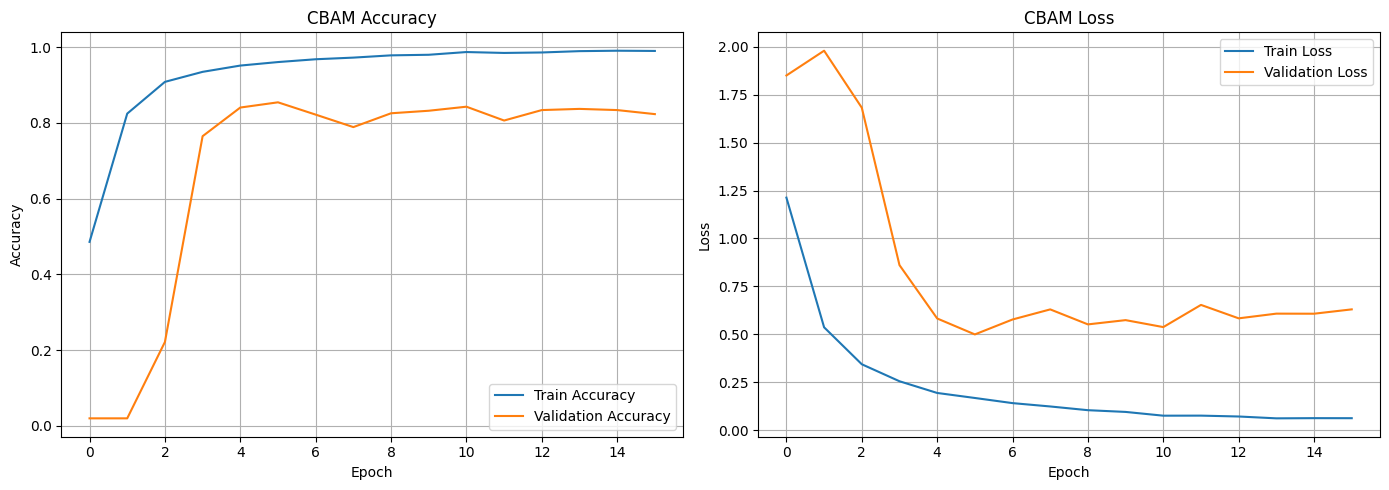


CBAM TEST RESULTS
Accuracy  : 0.8867
Precision : 0.8835
Recall    : 0.8143
Macro F1  : 0.8249

Classification Report
              precision    recall  f1-score   support

     WALKING     0.8804    0.9990    0.9360      1032
     JOGGING     0.9514    0.9982    0.9742       549
    UPSTAIRS     0.9932    0.4785    0.6459       303
  DOWNSTAIRS     0.7610    0.6996    0.7290       223
     SITTING     0.7151    1.0000    0.8339       133
    STANDING     1.0000    0.7105    0.8308       152

    accuracy                         0.8867      2392
   macro avg     0.8835    0.8143    0.8249      2392
weighted avg     0.8983    0.8867    0.8764      2392



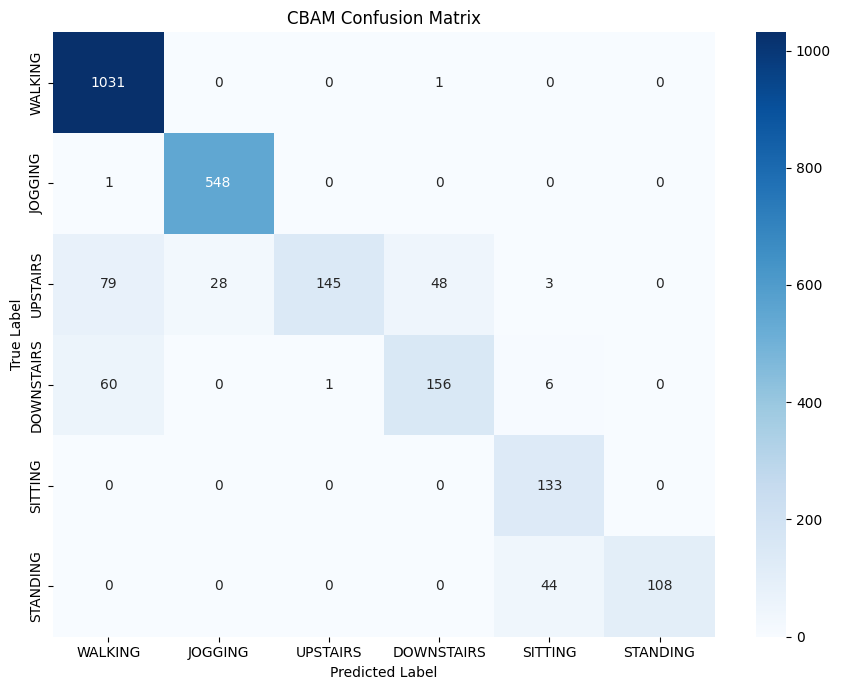


Final Results
Model  Accuracy  Precision   Recall  Macro F1
 CBAM  0.886706   0.883502 0.814306  0.824949


In [17]:
# ============================================================
# 19. TRAINING HISTORY
# ============================================================

plt.figure(figsize=(14, 5))


# Accuracy

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CBAM Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)


# Loss

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CBAM Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 20. TEST EVALUATION
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH,
    safe_mode=False
)

y_prob = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("\n================================")
print("CBAM TEST RESULTS")
print("================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Macro F1  : {f1:.4f}")

print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(N_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(N_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CBAM Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.tight_layout()

plt.show()


# ============================================================
# 22. SAVE RESULTS
# ============================================================

results = {
    "Model": "CBAM",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "Macro F1": f1
}

results_df = pd.DataFrame([results])

print("\nFinal Results")

print(results_df.to_string(index=False))